# Resultados 2026/02 (01/07 a 30/11/2026): ETL, KPIs e gráficos
Em um único código, lê a tabela de 2026/02, aplica o ETL, calcula os KPIs, mostra a tabela de resultados por mês e as metas SMART, usando somente os dados de 2026/02. A comparação com 2026/01 aparece apenas nos 3 gráficos finais.

Nota: a tabela de 2026/02 segue a estimativa de melhora do plano.

In [49]:
#=====================================================================
#RESULTADOS 2026/02 (01/07 a 30/11/2026): ETL, KPIs, tabela de resultados e gráficos
#Parte de 1 a 4: somente os dados de 2026/02.
#Parte 5: gráficos comparando com 2026/01.
#=====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ARQ_02 = "dados_consolidados_2026_02.csv"        # tabela de 2026/02 (analise)
ARQ_01 = "dados_consolidados_2026_01.csv"        # tabela de 2026/01 (só para os gráficos)

In [50]:
#=====================================================================
#1 - ETL: leitura, validação e limpeza da tabela de 2026/02
#=====================================================================
COLUNAS = ["data", "tempo_medio_entrega_min", "pedidos_com_atraso", "precisao_status_ciclo_%", "adocao_modulo_motoboy_%",
           "pedidos_recebidos", "pedidos_cancelados", "pedidos_entregues", "ticket_medio_rs", "faturamento_bruto_rs",
           "tempo_medio_preparo_min", "alimentos_descartados_kg", "uso_previsao_demanda_%"]
df = pd.read_csv(ARQ_02)
faltam = [c for c in COLUNAS if c not in df.columns]
if faltam:
    raise ValueError(f"Colunas ausentes em {ARQ_02}: {faltam}")
df["data"] = pd.to_datetime(df["data"], errors="coerce")
df = df.dropna(subset=["data"]).drop_duplicates("data").sort_values("data").reset_index(drop=True)
for c in COLUNAS[1:]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df[c] = df[c].fillna(df[c].median())
df["taxa_cancelamento_%"] = df["pedidos_cancelados"] / df["pedidos_recebidos"] * 100
df["taxa_atraso_%"] = df["pedidos_com_atraso"] / df["pedidos_recebidos"] * 100
df["mes"] = df["data"].dt.month

ok_entregues = ((df["pedidos_recebidos"] - df["pedidos_cancelados"]) == df["pedidos_entregues"]).all()
print(f"ETL 2026/02: {len(df)} dias ({df['data'].min():%d/%m/%Y} a {df['data'].max():%d/%m/%Y}) | "
      f"entregues = recebidos − cancelados: {'OK' if ok_entregues else 'divergência'}")
print("\nAmostra da tabela:")
print(df[COLUNAS].head(5).to_string(index=False))

ETL 2026/02: 153 dias (01/07/2026 a 30/11/2026) | entregues = recebidos − cancelados: OK

Amostra da tabela:
      data  tempo_medio_entrega_min  pedidos_com_atraso  precisao_status_ciclo_%  adocao_modulo_motoboy_%  pedidos_recebidos  pedidos_cancelados  pedidos_entregues  ticket_medio_rs  faturamento_bruto_rs  tempo_medio_preparo_min  alimentos_descartados_kg  uso_previsao_demanda_%
2026-07-01                    51.30                  15                    57.40                    58.70                 42                   5                 37            55.30              2,046.19                    43.50                     11.41                       0
2026-07-02                    49.90                  18                    52.50                    54.50                 41                   7                 34            55.30              1,880.28                    45.10                     11.76                       1
2026-07-03                    49.40                  19  

In [51]:
#=====================================================================
#2 - KPIs de 2026/02
#=====================================================================
K = {
    "cancel":   df["pedidos_cancelados"].sum() / df["pedidos_recebidos"].sum() * 100,
    "preparo":  df["tempo_medio_preparo_min"].mean(),
    "desp":     df["alimentos_descartados_kg"].mean(),
    "entrega":  df["tempo_medio_entrega_min"].mean(),
    "atraso":   df["pedidos_com_atraso"].sum() / df["pedidos_recebidos"].sum() * 100,
    "precisao": df["precisao_status_ciclo_%"].mean(),
    "adocao":   df["adocao_modulo_motoboy_%"].mean(),
}
print("\n" + "=" * 77)
print("KPIS EXTRAÍDOS E COMPROVADOS APÓS ETL CONSOLIDADO 2026/02")
print("=" * 77)
print(f"• Taxa de Cancelamento de Pedidos:        {K['cancel']:.2f}%")
print(f"• Tempo Médio de Preparo (Cozinha):       {K['preparo']:.2f} minutos")
print(f"• Desperdício Médio Diário:               {K['desp']:.2f} kg/dia")
print(f"• Tempo Médio de Entrega (Logística):     {K['entrega']:.2f} minutos")
print(f"• Taxa de Pedidos com Atraso:             {K['atraso']:.2f}%")
print(f"• Precisão do Status do Ciclo (Meta 95%): {K['precisao']:.2f}%")
print(f"• Adoção Módulo Motoboy (Meta 80%):       {K['adocao']:.2f}%")
print("=" * 77)


KPIS EXTRAÍDOS E COMPROVADOS APÓS ETL CONSOLIDADO 2026/02
• Taxa de Cancelamento de Pedidos:        12.81%
• Tempo Médio de Preparo (Cozinha):       39.23 minutos
• Desperdício Médio Diário:               11.00 kg/dia
• Tempo Médio de Entrega (Logística):     43.76 minutos
• Taxa de Pedidos com Atraso:             33.56%
• Precisão do Status do Ciclo (Meta 95%): 79.34%
• Adoção Módulo Motoboy (Meta 80%):       87.26%


In [52]:
#=====================================================================
#3 - TABELA DE RESULTADOS POR MÊS
#=====================================================================
nomes_mes = {7: "Julho", 8: "Agosto", 9: "Setembro", 10: "Outubro", 11: "Novembro"}
def resumo(g):
    return pd.Series({
        "Dias": len(g),
        "Pedidos recebidos/dia": g["pedidos_recebidos"].mean(),
        "Pedidos entregues/dia": g["pedidos_entregues"].mean(),
        "Cancelamento (%)": g["pedidos_cancelados"].sum() / g["pedidos_recebidos"].sum() * 100,
        "Preparo (min)": g["tempo_medio_preparo_min"].mean(),
        "Entrega (min)": g["tempo_medio_entrega_min"].mean(),
        "Atraso (%)": g["pedidos_com_atraso"].sum() / g["pedidos_recebidos"].sum() * 100,
        "Precisão (%)": g["precisao_status_ciclo_%"].mean(),
        "Adoção motoboy (%)": g["adocao_modulo_motoboy_%"].mean(),
        "Desperdício (kg/dia)": g["alimentos_descartados_kg"].mean(),
        "Ticket médio (R$)": g["faturamento_bruto_rs"].sum() / g["pedidos_entregues"].sum(),
        "Faturamento (R$)": g["faturamento_bruto_rs"].sum(),
    })
tabela = df.groupby("mes").apply(resumo)
tabela.index = [nomes_mes[m] for m in tabela.index]
tabela.loc["Total / média"] = resumo(df)
tabela.loc["Total / média", "Dias"] = len(df)
pd.options.display.float_format = "{:,.2f}".format
print("\nRESULTADOS 2026/02 POR MÊS")
print(tabela.round(2).to_string())
tabela.round(2).to_csv("resultados_2026_02.csv", encoding="utf-8-sig")


RESULTADOS 2026/02 POR MÊS
                Dias  Pedidos recebidos/dia  Pedidos entregues/dia  Cancelamento (%)  Preparo (min)  Entrega (min)  Atraso (%)  Precisão (%)  Adoção motoboy (%)  Desperdício (kg/dia)  Ticket médio (R$)  Faturamento (R$)
Julho          31.00                  46.58                  38.13             18.14          42.99          48.92       38.71         60.23               76.67                 11.86              55.43         65,515.77
Agosto         31.00                  49.26                  41.58             15.59          41.06          45.92       35.36         71.84               88.98                 11.82              56.51         72,835.70
Setembro       30.00                  48.03                  42.00             12.56          39.29          43.33       34.84         81.26               90.17                 10.94              57.29         72,184.09
Outubro        31.00                  48.87                  44.16              9.64        

/tmp/ipykernel_6337/2161115842.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabela = df.groupby("mes").apply(resumo)


In [53]:
#=====================================================================
#4 - METAS SMART
#=====================================================================
META = {"adocao": 80.0, "entrega": 44.2, "desp": 10.93, "precisao": 95.0}
m14 = df.set_index("data").rolling(14).mean()
def mantida_desde(cond):
    """Primeira data a partir da qual a meta é atingida e mantida até o fim do período."""
    m = cond.fillna(False)[::-1].cummin()[::-1]
    ok = m[m].index
    return ok[0].strftime("%d/%m/%Y") if len(ok) else "não atingida"
metas = [
    (f"Adoção do módulo de motoboy ≥ {META['adocao']:.0f}% (prazo 28/07/2026)",       mantida_desde(m14["adocao_modulo_motoboy_%"] >= META["adocao"])),
    (f"Redução de atrasos: tempo de entrega ≤ {META['entrega']} min (prazo 29/09/2026)", mantida_desde(m14["tempo_medio_entrega_min"] <= META["entrega"])),
    (f"Redução de desperdício: ≤ {META['desp']} kg/dia (prazo 31/03/2027)",            mantida_desde(m14["alimentos_descartados_kg"] <= META["desp"])),
    (f"Precisão do status do ciclo ≥ {META['precisao']:.0f}% (prazo 31/12/2026)",      mantida_desde(m14["precisao_status_ciclo_%"] >= META["precisao"])),
]
print("\nMETAS SMART (data a partir da qual a média de 14 dias atinge a meta e se mantém)")
for nome, dt in metas:
    print(f"  {'✅' if dt != 'não atingida' else '❌'} {nome:<78} -> {dt}")


METAS SMART (data a partir da qual a média de 14 dias atinge a meta e se mantém)
  ✅ Adoção do módulo de motoboy ≥ 80% (prazo 28/07/2026)                           -> 23/07/2026
  ✅ Redução de atrasos: tempo de entrega ≤ 44.2 min (prazo 29/09/2026)             -> 11/09/2026
  ✅ Redução de desperdício: ≤ 10.93 kg/dia (prazo 31/03/2027)                      -> 16/10/2026
  ✅ Precisão do status do ciclo ≥ 95% (prazo 31/12/2026)                           -> 22/11/2026


In [54]:
#=====================================================================
#5 - TRÊS GRÁFICOS: comparando com 2026/01
#=====================================================================
if os.path.exists(ARQ_01):
    d1 = pd.read_csv(ARQ_01, parse_dates=["data"])
    B = {"entrega": d1["tempo_medio_entrega_min"].mean(), "desp": d1["alimentos_descartados_kg"].mean(),
         "cancel": d1["pedidos_cancelados"].sum() / d1["pedidos_recebidos"].sum() * 100,
         "atraso": d1["pedidos_com_atraso"].sum() / d1["pedidos_recebidos"].sum() * 100,
         "precisao": d1["precisao_status_ciclo_%"].mean(), "adocao": d1["adocao_modulo_motoboy_%"].mean(),
         "fat_dia": d1["faturamento_bruto_rs"].mean()}
    fat01 = d1.groupby(d1["data"].dt.month)["faturamento_bruto_rs"].sum()
else:                                                           # valores já calculados da tabela de 2026/01
    B = {"entrega": 55.22, "desp": 12.86, "cancel": 19.20, "atraso": 43.71, "precisao": 52.69, "adocao": 25.14, "fat_dia": 2052.32}
    fat01 = pd.Series({1: 64185.0, 2: 56155.0, 3: 62590.0, 4: 62095.0, 5: 66935.0, 6: 59510.0})

semana = df.set_index("data").resample("W").mean(numeric_only=True)
semana = semana[semana.index <= pd.Timestamp(df["data"].max())]
if (df["data"].max().dayofweek != 6):                          # descarta a última semana se estiver incompleta
    semana = semana.iloc[:-1]

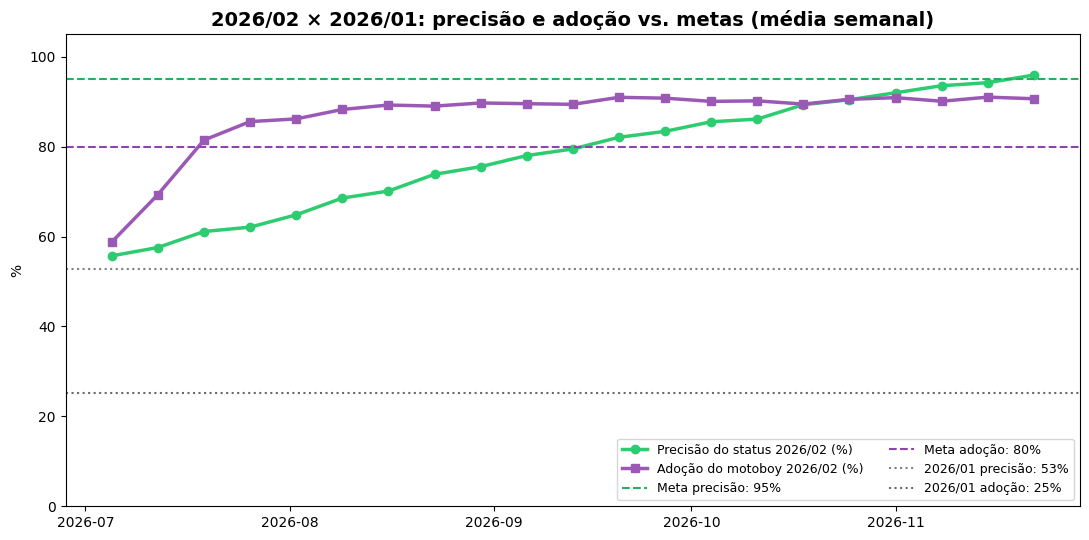

In [55]:
#Gráfico 1: precisão e adoção vs. metas e vs. 2026/01
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(semana.index, semana["precisao_status_ciclo_%"], marker="o", color="#2ecc71", linewidth=2.5, label="Precisão do status 2026/02 (%)")
ax.plot(semana.index, semana["adocao_modulo_motoboy_%"], marker="s", color="#9b59b6", linewidth=2.5, label="Adoção do motoboy 2026/02 (%)")
ax.axhline(95, color="#27ae60", linestyle="--", label="Meta precisão: 95%")
ax.axhline(80, color="#8e44ad", linestyle="--", label="Meta adoção: 80%")
ax.axhline(B["precisao"], color="gray", linestyle=":", label=f"2026/01 precisão: {B['precisao']:.0f}%")
ax.axhline(B["adocao"], color="dimgray", linestyle=":", label=f"2026/01 adoção: {B['adocao']:.0f}%")
ax.set_ylim(0, 105); ax.set_ylabel("%"); ax.legend(loc="lower right", fontsize=9, ncol=2)
ax.set_title("2026/02 × 2026/01: precisão e adoção vs. metas (média semanal)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

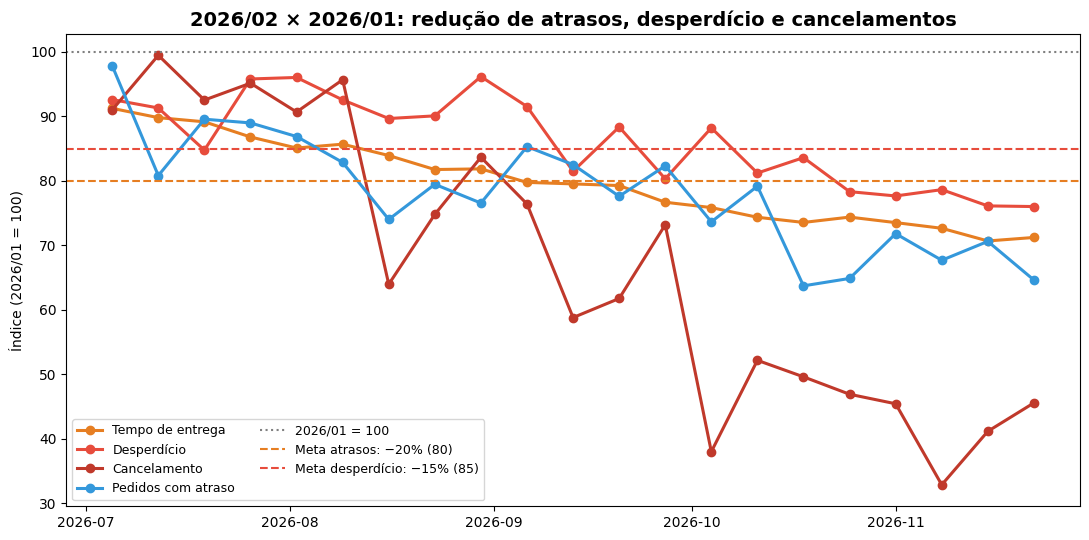

In [56]:
#Gráfico 2: redução de entrega, desperdício, cancelamento e atraso (índice: 2026/01 = 100)
fig, ax = plt.subplots(figsize=(11, 5.5))
series = {"Tempo de entrega": (semana["tempo_medio_entrega_min"], B["entrega"], "#e67e22"),
          "Desperdício": (semana["alimentos_descartados_kg"], B["desp"], "#e74c3c"),
          "Cancelamento": (semana["taxa_cancelamento_%"], B["cancel"], "#c0392b"),
          "Pedidos com atraso": (semana["taxa_atraso_%"], B["atraso"], "#3498db")}
for nome, (serie, base, cor) in series.items():
    ax.plot(semana.index, serie / base * 100, marker="o", linewidth=2.2, color=cor, label=nome)
ax.axhline(100, color="gray", linestyle=":", label="2026/01 = 100")
ax.axhline(80, color="#e67e22", linestyle="--", label="Meta atrasos: −20% (80)")
ax.axhline(85, color="#e74c3c", linestyle="--", label="Meta desperdício: −15% (85)")
ax.set_ylabel("Índice (2026/01 = 100)"); ax.legend(fontsize=9, ncol=2)
ax.set_title("2026/02 × 2026/01: redução de atrasos, desperdício e cancelamentos", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

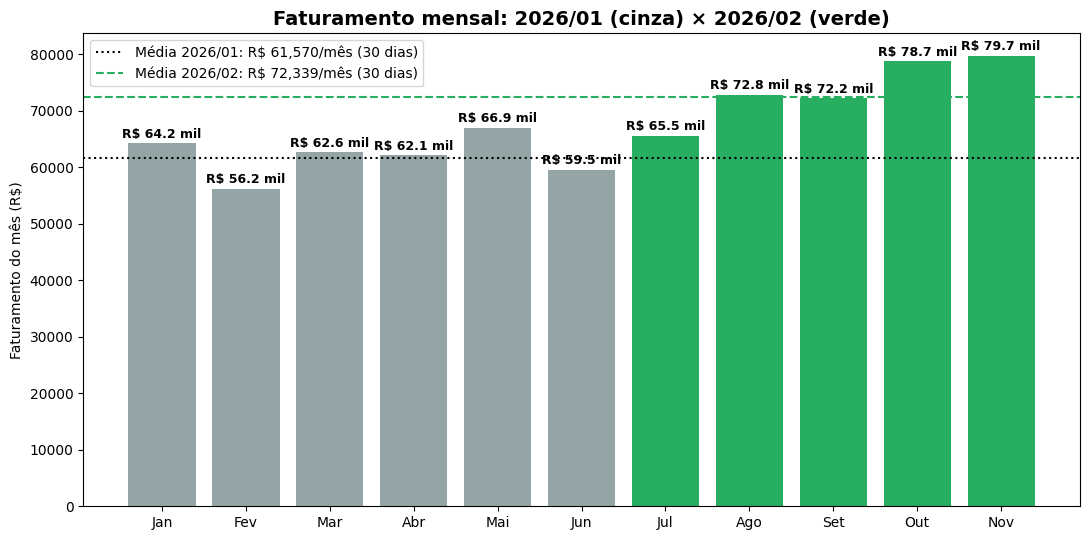

In [57]:
#Gráfico 3: faturamento mensal 2026/01 (cinza) × 2026/02 (verde)
fig, ax = plt.subplots(figsize=(11, 5.5))
nm = {1: "Jan", 2: "Fev", 3: "Mar", 4: "Abr", 5: "Mai", 6: "Jun", 7: "Jul", 8: "Ago", 9: "Set", 10: "Out", 11: "Nov"}
fat02 = df.groupby("mes")["faturamento_bruto_rs"].sum()
rotulos = [nm[m] for m in fat01.index] + [nm[m] for m in fat02.index]
valores = list(fat01.values) + list(fat02.values)
barras = ax.bar(rotulos, valores, color=["#95a5a6"] * len(fat01) + ["#27ae60"] * len(fat02))
for b_, v in zip(barras, valores):
    ax.annotate(f"R$ {v / 1000:,.1f} mil", (b_.get_x() + b_.get_width() / 2, v), xytext=(0, 4), textcoords="offset points",
                ha="center", fontweight="bold", fontsize=9)
ax.axhline(B["fat_dia"] * 30, color="black", linestyle=":", label=f"Média 2026/01: R$ {B['fat_dia'] * 30:,.0f}/mês (30 dias)")
ax.axhline(df["faturamento_bruto_rs"].mean() * 30, color="#27ae60", linestyle="--",
           label=f"Média 2026/02: R$ {df['faturamento_bruto_rs'].mean() * 30:,.0f}/mês (30 dias)")
ax.set_ylabel("Faturamento do mês (R$)"); ax.legend(loc="upper left")
ax.set_title("Faturamento mensal: 2026/01 (cinza) × 2026/02 (verde)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [58]:
#Baixa a tabela de resultados por mês
try:
    from google.colab import files
    files.download("resultados_2026_02.csv")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>